In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


### Distribution of movie budgets (histogram/KDE).

In [2]:
DATA_PATH = "../TMDB_data/cleaned/"

movies = pd.read_csv(DATA_PATH + "movies_cleaned.csv")

print("Movies dataset loaded:", movies.shape)

Movies dataset loaded: (2503, 13)


In [8]:
genres = pd.read_csv(DATA_PATH + "genres_cleaned.csv")

movie_genres = pd.read_csv(DATA_PATH + "movie_genres_cleaned.csv")

cast = pd.read_csv(DATA_PATH + "cast_cleaned.csv")

crew = pd.read_csv(DATA_PATH + "crew_cleaned.csv")

movie_keywords = pd.read_csv(DATA_PATH + "movie_keywords_cleaned.csv")

print("All datasets loaded successfully!")

All datasets loaded successfully!


In [3]:
sns.set_theme(style="whitegrid")

plt.rcParams["figure.figsize"] = (10, 6)

In [4]:
budget_data = movies[movies["budget"] > 0].copy()

# Convert budget into millions
budget_data["budget_millions"] = (
    budget_data["budget"] / 1000000
)

print("Movies included:", len(budget_data))

Movies included: 2413


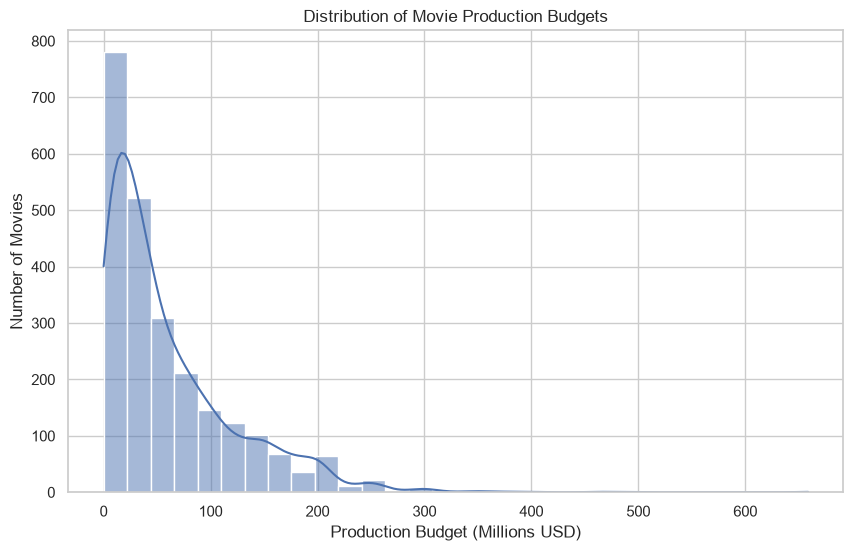

In [ ]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=budget_data,
    x="budget_millions",
    bins=30,
    kde=True
)

plt.title("Distribution of Movie Production Budgets")
plt.xlabel("Production Budget (Millions USD)")
plt.ylabel("Number of Movies")

plt.show()

##right-skewed distribution (positively skewed).

### Movie Runtime Distribution

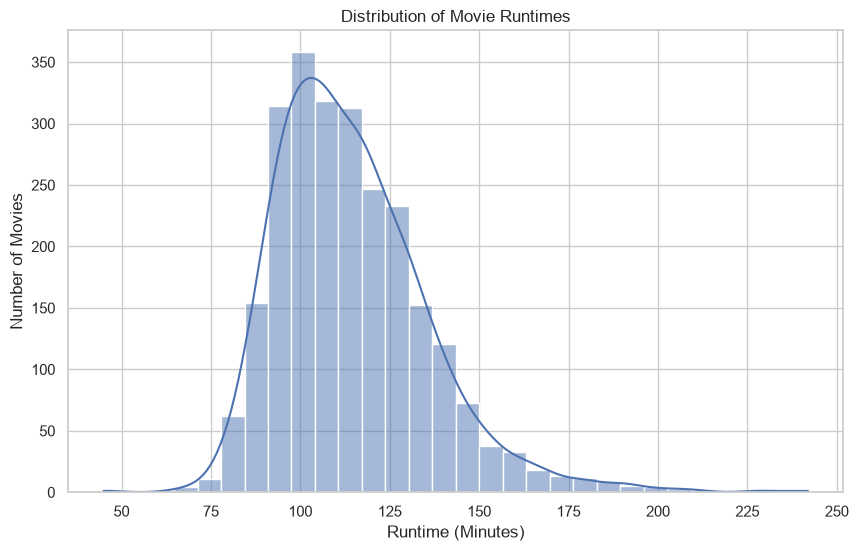

In [ ]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=movies[movies["runtime"] > 0],
    x="runtime",
    bins=30,
    kde=True
)

plt.title("Distribution of Movie Runtimes")
plt.xlabel("Runtime (Minutes)")
plt.ylabel("Number of Movies")

plt.show()

#runtime distribution is slightly right-skewed (positively skewed).

### Movie Rating Distribution

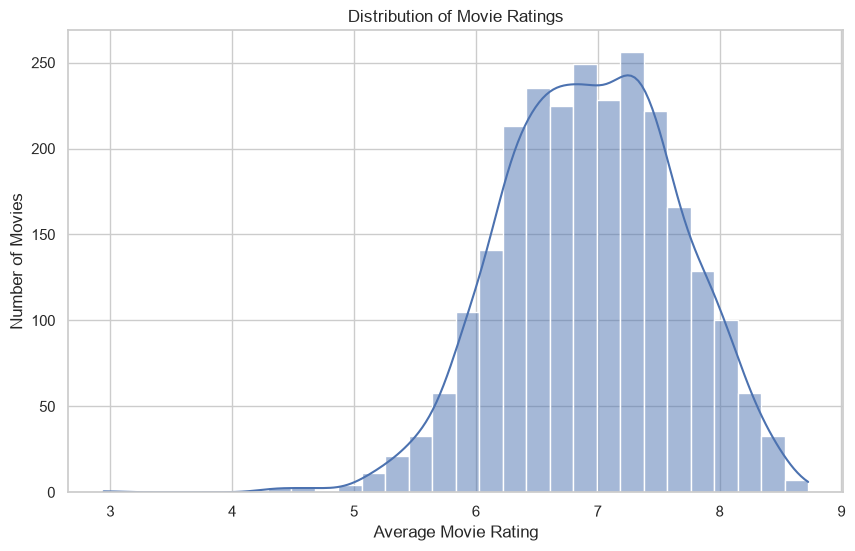

In [ ]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=movies,
    x="vote_average",
    bins=30,
    kde=True
)

plt.title("Distribution of Movie Ratings")
plt.xlabel("Average Movie Rating")
plt.ylabel("Number of Movies")

plt.show()

#movie rating distribution is approximately bell-shaped, with most ratings concentrated between 6 and 8.

### Number of Movies per Genre

In [9]:

genre_data = movie_genres.merge(
    genres,
    on="genre_id",
    how="left"
)

genre_data.head()

,movie_id,genre_id,genre_name
0,157336,12,Adventure
1,157336,18,Drama
2,157336,878,Science Fiction
3,27205,28,Action
4,27205,878,Science Fiction


In [10]:
genre_counts = (
    genre_data.groupby("genre_name")["movie_id"]
    .nunique()
    .sort_values(ascending=False)
)

genre_counts

genre_name
Drama              937
Action             808
Comedy             762
Adventure          674
Thriller           673
Science Fiction    463
Fantasy            396
Crime              387
Romance            349
Family             344
Horror             339
Animation          246
Mystery            216
History            112
War                 85
Music               49
Western             33
TV Movie             4
Documentary          1
Name: movie_id, dtype: int64

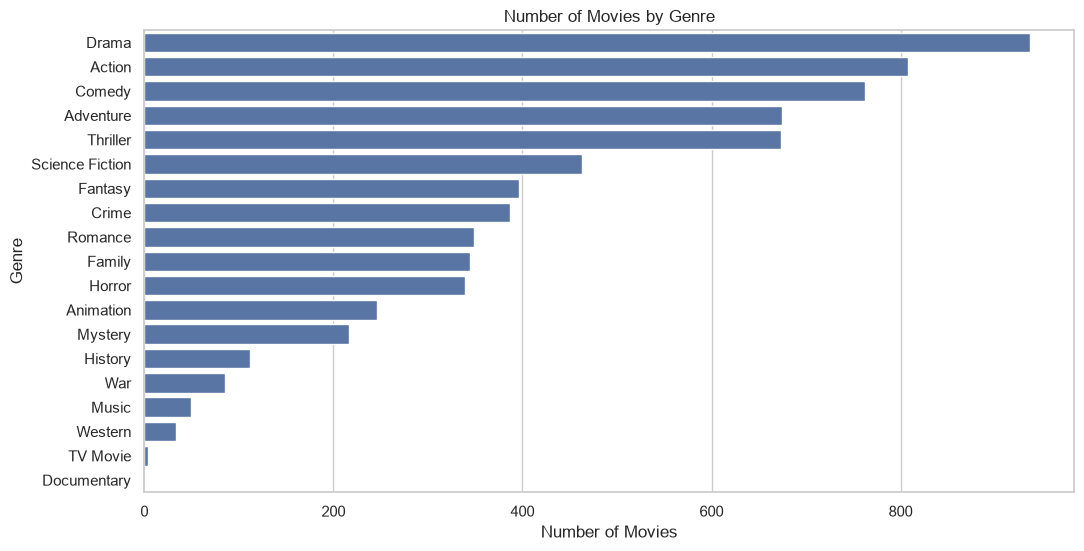

In [11]:
plt.figure(figsize=(12, 6))

sns.barplot(
    x=genre_counts.values,
    y=genre_counts.index
)

plt.title("Number of Movies by Genre")
plt.xlabel("Number of Movies")
plt.ylabel("Genre")

plt.show()

### Movie Budget vs Revenue

In [12]:
financial_movies = movies[
    (movies["budget"] > 0) &
    (movies["revenue"] > 0)
].copy()

financial_movies["budget_millions"] = (
    financial_movies["budget"] / 1000000
)

financial_movies["revenue_millions"] = (
    financial_movies["revenue"] / 1000000
)

print("Movies included:", len(financial_movies))

Movies included: 2370


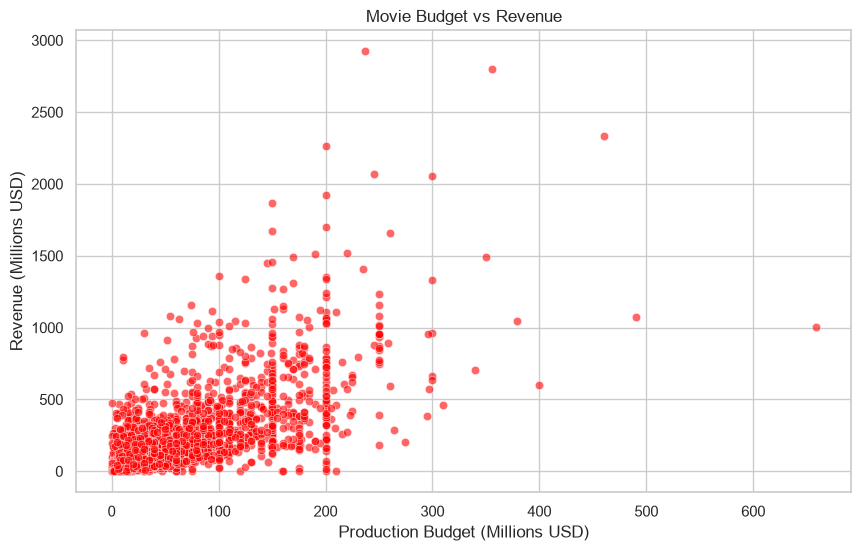

In [16]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=financial_movies,
    color="red",
    x="budget_millions",
    y="revenue_millions",
    alpha=0.6
)

plt.title("Movie Budget vs Revenue")
plt.xlabel("Production Budget (Millions USD)")
plt.ylabel("Revenue (Millions USD)")

plt.show()

### Movie Popularity vs Vote Count

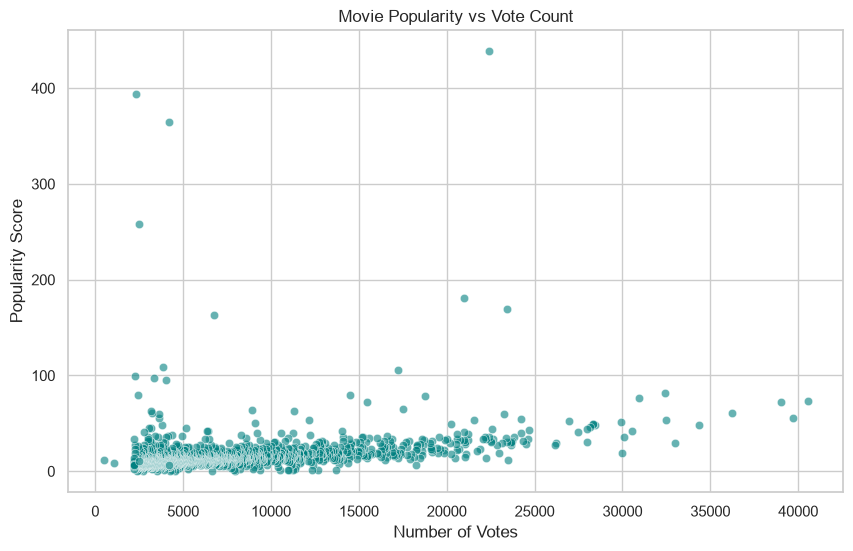

In [19]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=movies,
    x="vote_count",
    y="popularity",
    color="teal",
    alpha=0.6
)

plt.title("Movie Popularity vs Vote Count")
plt.xlabel("Number of Votes")
plt.ylabel("Popularity Score")

plt.show()

### Average Rating by Genre

In [20]:
rating_genre_data = movie_genres.merge(
    genres,
    on="genre_id",
    how="left"
)

rating_genre_data = rating_genre_data.merge(
    movies[["movie_id", "vote_average"]],
    on="movie_id",
    how="left"
)

In [21]:
genre_ratings = (
    rating_genre_data
    .groupby("genre_name")["vote_average"]
    .mean()
    .sort_values(ascending=False)
)

genre_ratings

genre_name
War                7.357576
History            7.335509
Music              7.324755
Documentary        7.310000
Drama              7.252454
Animation          7.204341
Western            7.131030
Romance            7.033762
TV Movie           7.013500
Crime              7.006690
Family             6.935552
Mystery            6.879625
Thriller           6.861853
Adventure          6.834755
Fantasy            6.825242
Science Fiction    6.814102
Comedy             6.809316
Action             6.729059
Horror             6.621224
Name: vote_average, dtype: float64

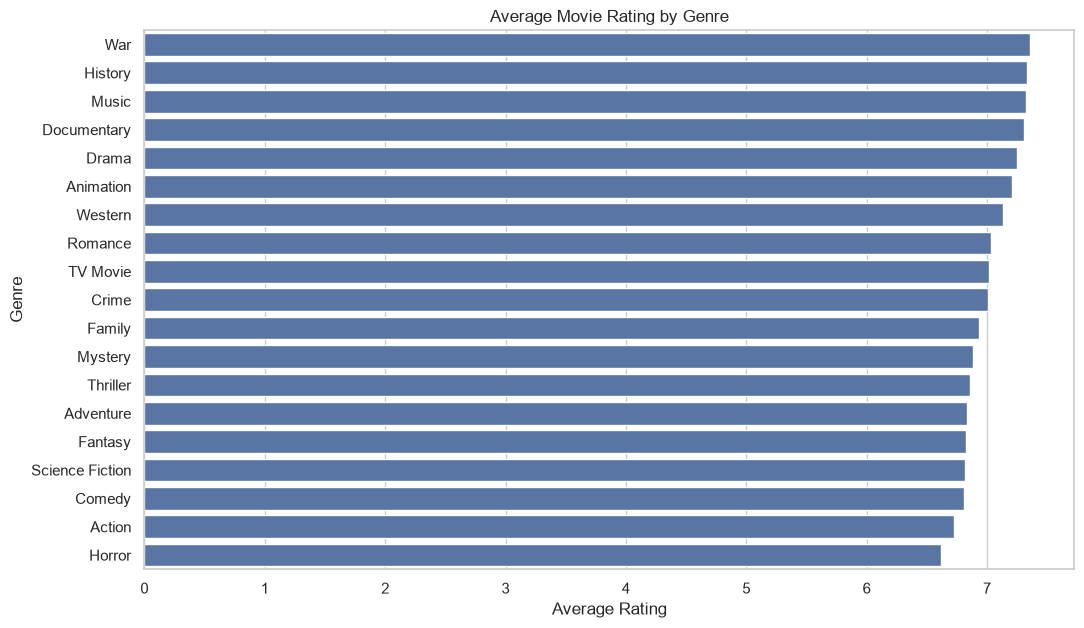

In [22]:
plt.figure(figsize=(12, 7))

sns.barplot(
    x=genre_ratings.values,
    y=genre_ratings.index
)

plt.title("Average Movie Rating by Genre")
plt.xlabel("Average Rating")
plt.ylabel("Genre")

plt.show()

### Movies Released per Year

   release_year  total_movies
0          1921             1
1          1922             1
2          1927             1
3          1931             2
4          1936             1


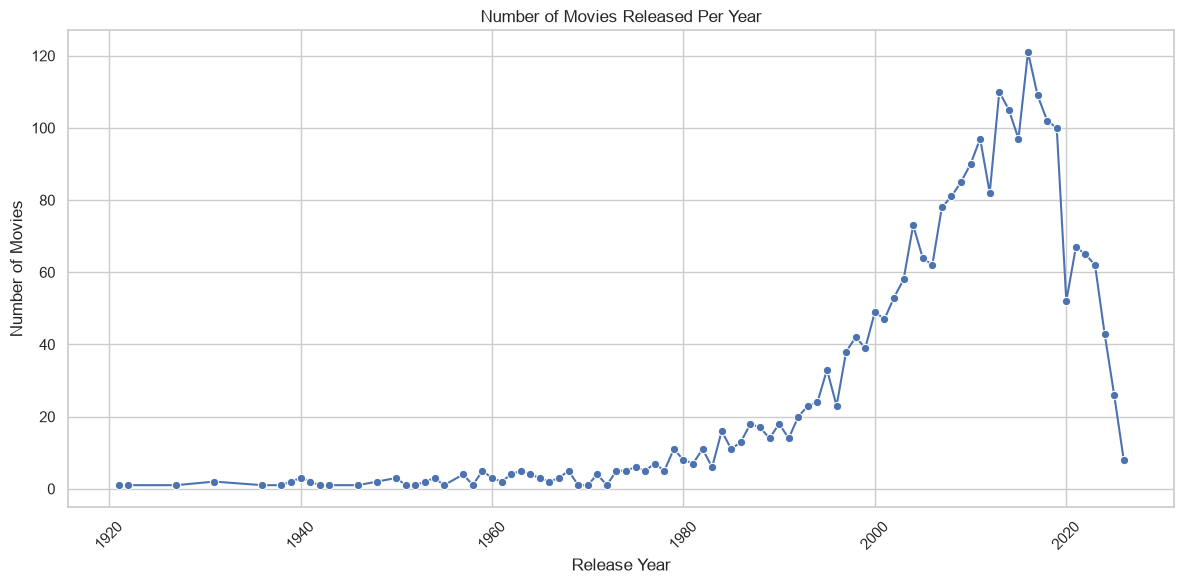

In [ ]:
movies_yearly = (
    movies.groupby("release_year")["movie_id"]
    .nunique()
    .reset_index(name="total_movies")
)

movies_yearly.head()

print(movies_yearly.head())

plt.figure(figsize=(12, 6))

sns.lineplot(
    data=movies_yearly,
    x="release_year",
    y="total_movies",
    marker="o"
)

plt.title("Number of Movies Released Per Year")
plt.xlabel("Release Year")
plt.ylabel("Number of Movies")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Correlation heatmap of budget, revenue, runtime, popularity, vote_average and vote_count (heatmap).

In [25]:
correlation_data = financial_movies[
    [
        "budget",
        "revenue",
        "popularity",
        "vote_average",
        "vote_count",
        "runtime"
    ]
]

correlation_matrix = correlation_data.corr()

correlation_matrix

,budget,revenue,popularity,vote_average,vote_count,runtime
budget,1.000000,0.677668,0.247534,-0.123263,0.368284,0.299779
revenue,0.677668,1.000000,0.376841,0.088478,0.607222,0.248042
popularity,0.247534,0.376841,1.000000,0.231528,0.356106,0.179336
vote_average,-0.123263,0.088478,0.231528,1.000000,0.390783,0.333335
vote_count,0.368284,0.607222,0.356106,0.390783,1.000000,0.282404
runtime,0.299779,0.248042,0.179336,0.333335,0.282404,1.000000


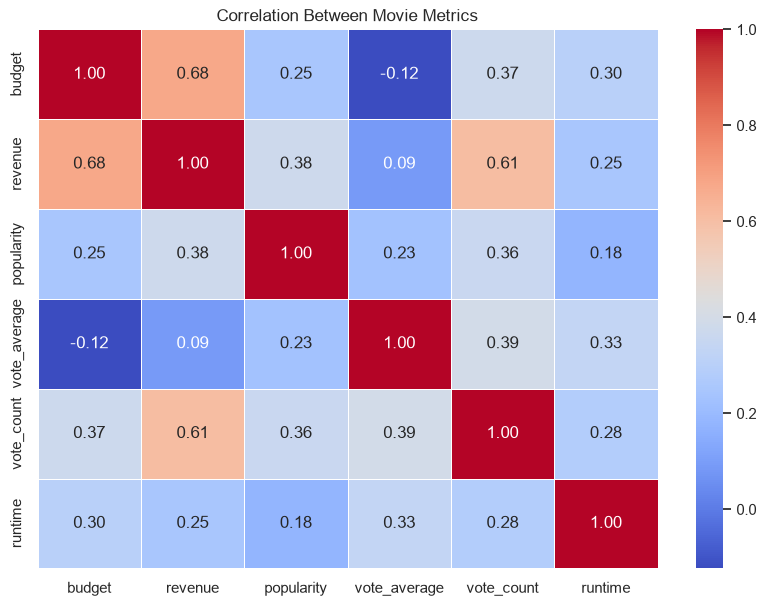

In [26]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Between Movie Metrics")

plt.show()

### Pairplot of budget, revenue, popularity and vote_average, colored by primary genre (pairplot).

In [ ]:
#Prepare the primary genre
# Preserve the original genre order
movie_genres_ordered = movie_genres.copy()

movie_genres_ordered["genre_order"] = (
    movie_genres_ordered.groupby("movie_id").cumcount()
)

# Select the first genre for every movie
primary_genres = movie_genres_ordered[
    movie_genres_ordered["genre_order"] == 0
].merge(
    genres,
    on="genre_id",
    how="left"
)

primary_genres = primary_genres[
    ["movie_id", "genre_name"]
]

In [ ]:
#Combine financial data and primary genre
pairplot_data = financial_movies.merge(
    primary_genres,
    on="movie_id",
    how="inner"
)

pairplot_data = pairplot_data.rename(
    columns={"genre_name": "primary_genre"}
)

# Convert budget and revenue into millions
pairplot_data["budget"] = (
    pairplot_data["budget"] / 1000000
)

pairplot_data["revenue"] = (
    pairplot_data["revenue"] / 1000000
)

print("Movies included:", len(pairplot_data))

pairplot_data.head()

Movies included: 2366


,movie_id,title,original_language,release_date,runtime,budget,revenue,popularity,vote_average,vote_count,status,overview,release_year,budget_millions,revenue_millions,primary_genre
0,157336,Interstellar,en,2014-11-05,169,165.0,746.606706,73.0452,8.484,40566,Released,The adventures of a group of explorers who mak...,2014,165.0,746.606706,Adventure
1,27205,Inception,en,2010-07-15,148,160.0,839.030630,55.8497,8.400,39727,Released,"Cobb, a skilled thief who commits corporate es...",2010,160.0,839.030630,Action
2,24428,The Avengers,en,2012-04-25,143,220.0,1518.815515,72.2515,8.062,38993,Released,When an unexpected enemy emerges and threatens...,2012,220.0,1518.815515,Science Fiction
3,155,The Dark Knight,en,2008-07-16,152,185.0,1004.558444,60.5510,8.534,36255,Released,Batman raises the stakes in his war on crime. ...,2008,185.0,1004.558444,Action
4,19995,Avatar,en,2009-12-16,162,237.0,2923.706026,48.1996,7.610,34348,Released,"In the 22nd century, a paraplegic Marine is di...",2009,237.0,2923.706026,Action


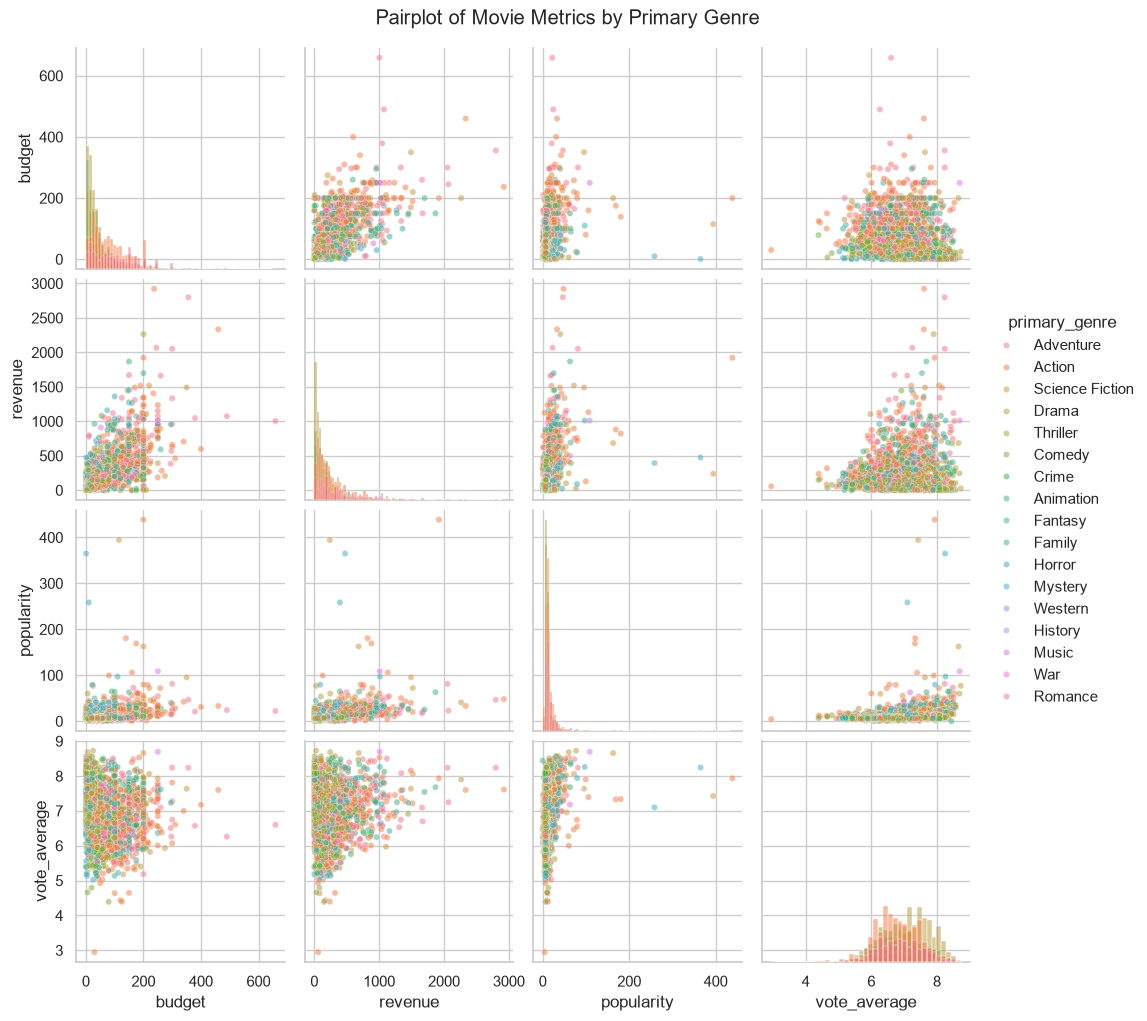

In [29]:
sns.pairplot(
    data=pairplot_data,
    vars=[
        "budget",
        "revenue",
        "popularity",
        "vote_average"
    ],
    hue="primary_genre",
    diag_kind="hist",
    height=2.5,
    plot_kws={"alpha": 0.5, "s": 20}
)

plt.suptitle(
    "Pairplot of Movie Metrics by Primary Genre",
    y=1.02
)

plt.show()

### Budget vs revenue colored by primary genre, with point size showing vote_count (scatter plot with hue and size).

In [30]:
pairplot_data[
    [
        "title",
        "budget",
        "revenue",
        "vote_count",
        "primary_genre"
    ]
].head()

,title,budget,revenue,vote_count,primary_genre
0,Interstellar,165.0,746.606706,40566,Adventure
1,Inception,160.0,839.030630,39727,Action
2,The Avengers,220.0,1518.815515,38993,Science Fiction
3,The Dark Knight,185.0,1004.558444,36255,Action
4,Avatar,237.0,2923.706026,34348,Action


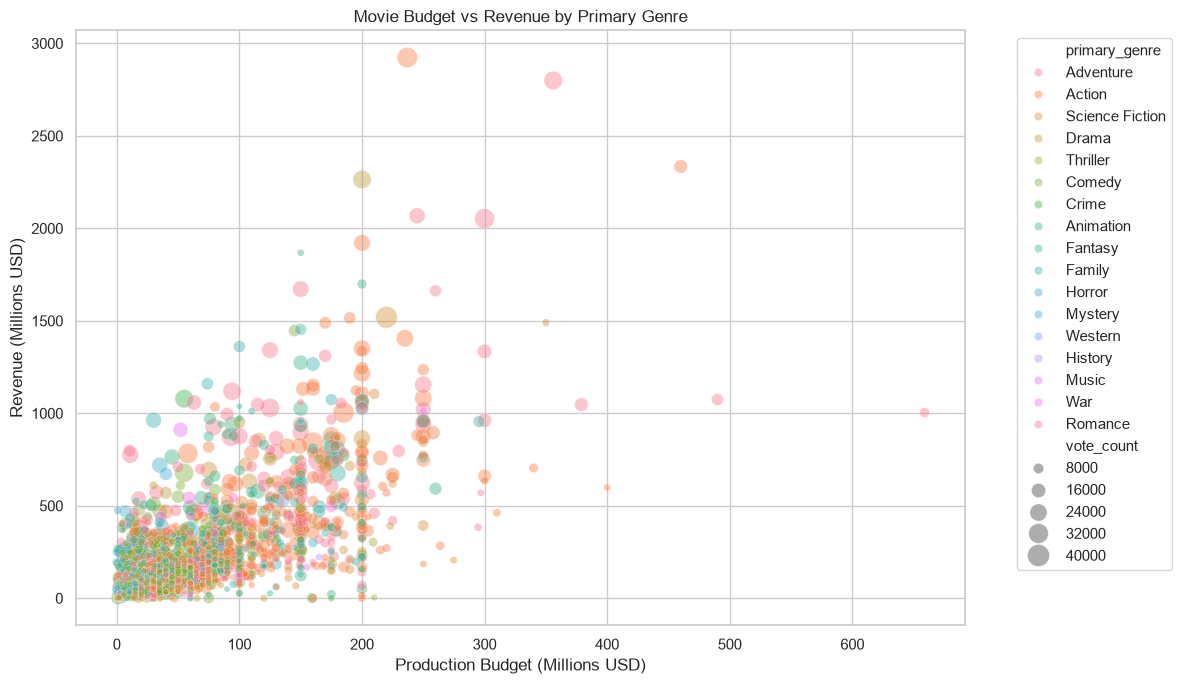

In [32]:
plt.figure(figsize=(12, 7))

sns.scatterplot(
    data=pairplot_data,
    x="budget",
    y="revenue",
    hue="primary_genre",
    size="vote_count",
    sizes=(20, 250),
    alpha=0.4
)

plt.title("Movie Budget vs Revenue by Primary Genre")
plt.xlabel("Production Budget (Millions USD)")
plt.ylabel("Revenue (Millions USD)")

plt.legend(
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()

### Distribution of vote_average for each genre in separate panels (FacetGrid with histograms).

In [33]:
genre_rating_data = movies[
    ["movie_id", "vote_average"]
].merge(
    primary_genres,
    on="movie_id",
    how="inner"
)

# Remove missing ratings
genre_rating_data = genre_rating_data.dropna(
    subset=["vote_average"]
)

genre_rating_data = genre_rating_data.rename(
    columns={"genre_name": "primary_genre"}
)

print("Movies included:", len(genre_rating_data))

genre_rating_data.head()

Movies included: 2499


,movie_id,vote_average,primary_genre
0,157336,8.484,Adventure
1,27205,8.400,Action
2,24428,8.062,Science Fiction
3,155,8.534,Action
4,19995,7.610,Action


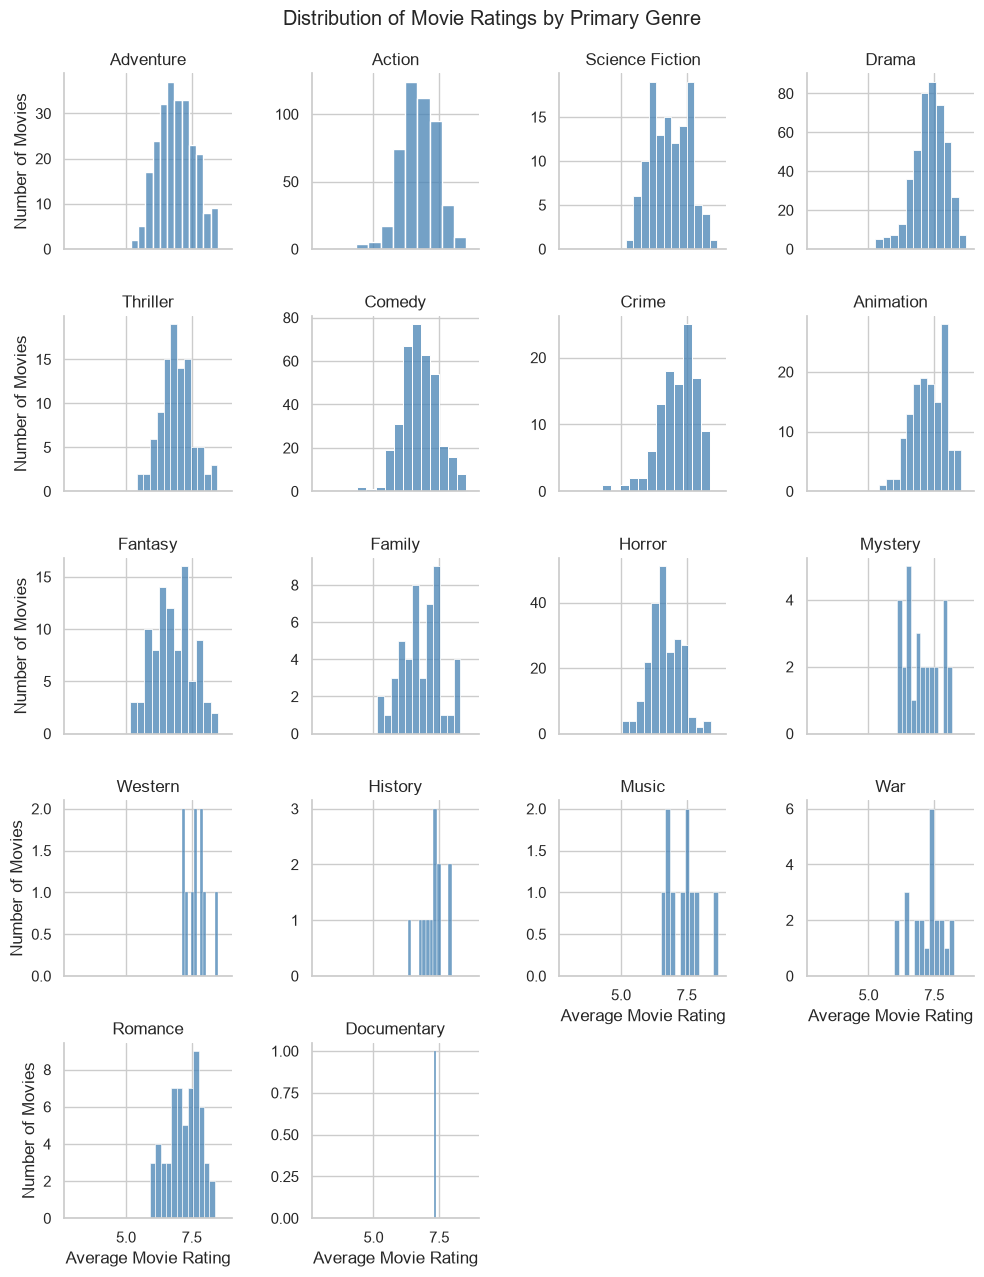

In [34]:
g = sns.FacetGrid(
    data=genre_rating_data,
    col="primary_genre",
    col_wrap=4,
    height=2.5,
    sharex=True,
    sharey=False
)

g.map_dataframe(
    sns.histplot,
    x="vote_average",
    bins=12,
    color="steelblue"
)

g.set_axis_labels(
    "Average Movie Rating",
    "Number of Movies"
)

g.set_titles("{col_name}")

g.fig.suptitle(
    "Distribution of Movie Ratings by Primary Genre",
    y=1.02
)

plt.show()

### Average revenue by genre and release decade (heatmap of a pivot table).

In [40]:
revenue_genre_data = movie_genres.merge(
    genres,
    on="genre_id",
    how="left"
)

revenue_genre_data = revenue_genre_data.merge(
    movies[["movie_id", "release_year", "revenue"]],
    on="movie_id",
    how="left"
)

revenue_genre_data.head()

,movie_id,genre_id,genre_name,release_year,revenue
0,157336,12,Adventure,2014,746606706.0
1,157336,18,Drama,2014,746606706.0
2,157336,878,Science Fiction,2014,746606706.0
3,27205,28,Action,2010,839030630.0
4,27205,878,Science Fiction,2010,839030630.0


In [41]:

#Clean and prepare revenue
revenue_genre_data = revenue_genre_data.dropna(
    subset=["release_year", "revenue"]
)

revenue_genre_data = revenue_genre_data[
    revenue_genre_data["revenue"] > 0
].copy()

In [42]:
#Convert revenue into millions:
revenue_genre_data["revenue_millions"] = (
    revenue_genre_data["revenue"] / 1000000
)

In [44]:
##Create the release decade column
revenue_genre_data["release_decade"] = (
    (revenue_genre_data["release_year"] // 10) * 10
)

revenue_genre_data[
    ["movie_id", "release_year", "release_decade", "revenue_millions"]
].head(10)

,movie_id,release_year,release_decade,revenue_millions
0,157336,2014,2010,746.606706
1,157336,2014,2010,746.606706
2,157336,2014,2010,746.606706
3,27205,2010,2010,839.030630
4,27205,2010,2010,839.030630
5,27205,2010,2010,839.030630
6,24428,2012,2010,1518.815515
7,24428,2012,2010,1518.815515
8,24428,2012,2010,1518.815515
9,155,2008,2000,1004.558444


In [45]:
genre_decade_revenue = revenue_genre_data.pivot_table(
    index="genre_name",
    columns="release_decade",
    values="revenue_millions",
    aggfunc="mean"
)

genre_decade_revenue

release_decade,1920,1930,1940,1950,1960,1970,1980,1990,2000,2010,2020
genre_name,,,,,,,,,,,
Action,NaN,NaN,NaN,105.000000,91.364937,197.010881,169.434254,251.429134,280.882623,350.416829,335.921340
Adventure,NaN,33.754967,NaN,71.646807,120.234432,233.186886,180.485054,307.887994,357.052741,486.751461,434.319160
Animation,NaN,184.925486,127.364742,99.231807,234.400000,131.005290,76.522808,278.246393,316.082894,480.002873,450.845703
Comedy,5.450000,3.025000,11.000000,20.139759,92.507551,111.748437,135.896721,192.093583,212.887841,234.485821,318.550429
Crime,NaN,0.035274,2.200000,9.372556,NaN,76.504227,154.526562,127.500074,150.139243,161.056991,193.549814
Drama,3.400161,102.109463,52.236989,34.267201,49.279550,99.699001,101.484540,183.002457,144.090462,143.478141,158.550636
Family,NaN,109.340226,103.820619,99.231807,218.502857,98.844417,124.020084,271.615214,283.477318,468.768766,478.240210
Fantasy,0.027964,109.340226,83.351981,92.022242,62.650000,59.047104,105.418921,197.318377,308.572916,369.938619,337.681284
History,NaN,NaN,NaN,104.454000,65.000000,31.500000,63.066017,217.737402,152.361199,130.384072,173.784980


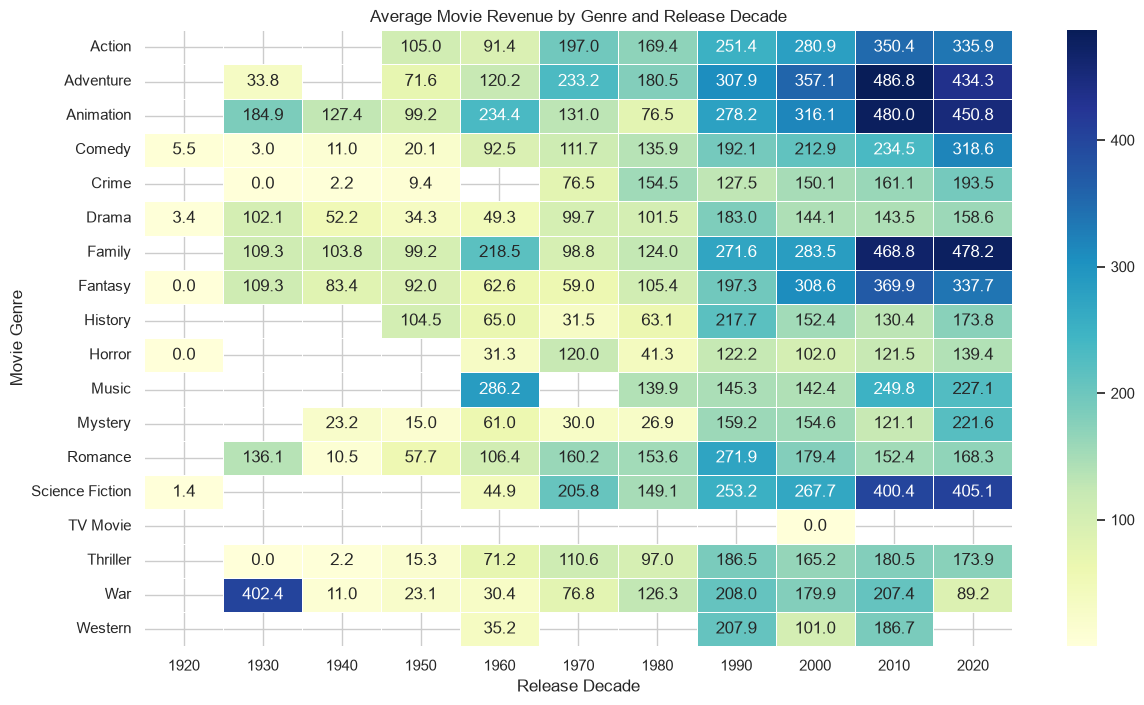

In [46]:
plt.figure(figsize=(14, 8))

sns.heatmap(
    genre_decade_revenue,
    cmap="YlGnBu",
    annot=True,
    fmt=".1f",
    linewidths=0.5
)

plt.title("Average Movie Revenue by Genre and Release Decade")
plt.xlabel("Release Decade")
plt.ylabel("Movie Genre")

plt.show()